# ⚙️ PartSight: Identifying Marine Diesel Engine Parts with AlexNet
**Mathematics of Data Science — Final Project (Deliverable 3)**
**Author:** Ziya Batur Koroglu · Fall 2026

**Problem.** Marine diesel parts suppliers receive photos of worn or unlabeled parts from ship engineers and need to identify them quickly to quote and source replacements. This notebook trains **AlexNet** to classify photos of six common marine diesel / generator engine parts:

| Class | Why it matters |
|---|---|
| `fuel_injector` | Most frequently replaced wear part on generator engines |
| `turbocharger` | High-value part; fast ID speeds up quotes |
| `piston` | Overhaul item, many sizes and crown shapes |
| `connecting_rod` | Often confused with other forged parts |
| `crankshaft` | Large, expensive, long lead time |
| `oil_filter` | High-volume consumable |

**What this notebook does**
1. Builds a labeled image dataset (auto-download **or** your own photos from Google Drive)
2. Preprocesses images for AlexNet (224×224, ImageNet normalization, optional augmentation)
3. Trains and validates AlexNet with transfer learning, tracking accuracy and loss
4. Runs the required experiments: **batch size**, **learning rate**, **data augmentation**, and **AlexNet vs. ResNet18**
5. Logs every run to **Weights & Biases**, and saves plots, confusion matrices and model weights

> ▶️ **Before running:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`. Total time ≈ 15–25 minutes.

## 1. Setup & imports

In [30]:
!pip install -q wandb icrawler imagehash

import os, random, shutil, hashlib, json, time, copy, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import wandb

warnings.filterwarnings("ignore")

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {device}")
if device.type == "cpu":
    print("⚠️  No GPU found. Switch to Runtime → Change runtime type → T4 GPU for much faster training.")

BASE = "/content" if os.path.exists("/content") else os.getcwd()
RAW_DIR   = os.path.join(BASE, "raw_images")
DATA_DIR  = os.path.join(BASE, "data")
FIG_DIR   = os.path.join(BASE, "figures")
MODEL_DIR = os.path.join(BASE, "models")
for d in [RAW_DIR, DATA_DIR, FIG_DIR, MODEL_DIR]:
    os.makedirs(d, exist_ok=True)

✅ Using device: cuda


## 2. Project configuration
Change values here, not further down. `DATA_SOURCE` options:
- `"download"` — automatically collects web images for each class (default, needs no setup)
- `"drive"` — uses your own photos from Google Drive, arranged as `DRIVE_FOLDER/<class_name>/*.jpg`

In [31]:
DATA_SOURCE  = "download"   # "download" or "drive"
DRIVE_FOLDER = "/content/drive/MyDrive/PartSight/raw_images"   # used only when DATA_SOURCE == "drive"

NEG = ""
CLASSES = {   # many searches per part: each search returns only ~35 images
    "fuel_injector":  ["diesel fuel injector nozzle part", "diesel generator fuel injector spare part", "common rail diesel injector",
                       "bosch diesel injector", "denso diesel injector", "cummins fuel injector", "caterpillar fuel injector",
                       "remanufactured diesel injector", "fuel injector product photo", "diesel injector isolated white background"],
    "turbocharger":   ["diesel engine turbocharger part", "ship engine turbocharger", "turbocharger product photo", "garrett turbocharger",
                       "holset turbocharger", "borgwarner turbocharger", "remanufactured turbocharger", "truck turbocharger",
                       "turbocharger isolated white background", "generator engine turbocharger"],
    "piston":         ["diesel engine piston part", "diesel piston with rings", "engine piston isolated", "mahle piston",
                       "truck engine piston", "piston product photo", "forged piston", "cast aluminum engine piston",
                       "diesel piston crown", "generator engine piston"],
    "connecting_rod": ["diesel engine connecting rod part", "engine connecting rod spare part", "forged connecting rod isolated",
                       "connecting rod product photo", "truck engine connecting rod", "con rod engine part", "h beam connecting rod",
                       "used connecting rod", "connecting rod with bearing", "generator engine connecting rod"],
    "crankshaft":     ["engine crankshaft spare part", "crankshaft isolated", "ship engine crankshaft", "diesel crankshaft product",
                       "truck engine crankshaft", "forged crankshaft", "crankshaft product photo", "crankshaft white background",
                       "remanufactured crankshaft", "generator engine crankshaft"],
    "oil_filter":     ["diesel engine oil filter", "spin-on oil filter cartridge", "heavy duty oil filter part", "truck engine oil filter",
                       "fleetguard oil filter", "baldwin oil filter", "oil filter product photo", "oil filter isolated white background",
                       "cartridge oil filter element", "generator oil filter"],
}
IMAGES_PER_QUERY = 100
SPLIT = (0.70, 0.15, 0.15)     # train / validation / test
IMG_SIZE = 224                 # AlexNet input size
EPOCHS = 15
MIN_CLIP_PROB = 0.40           # photo filter strictness (higher = stricter, fewer images)

WANDB_PROJECT = "partsight-alexnet"
WANDB_MODE = "online"

## 3. Build the dataset

In [32]:
!pip install -q ddgs

def download_images():
    # DuckDuckGo image search (Bing via icrawler started returning random, unrelated images)
    from ddgs import DDGS
    import requests, concurrent.futures as cf
    headers = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36"}

    def fetch(job):
        url, path = job
        try:
            r = requests.get(url, headers=headers, timeout=10)
            if r.status_code == 200 and r.headers.get("content-type", "").startswith("image") and len(r.content) > 5000:
                with open(path, "wb") as f:
                    f.write(r.content)
                return 1
        except Exception:
            pass
        return 0

    for cls, queries in CLASSES.items():
        out = os.path.join(RAW_DIR, cls)
        os.makedirs(out, exist_ok=True)
        urls = []
        for q in queries:
            res = []
            for attempt in range(4):
                try:
                    res = DDGS().images(q + NEG, max_results=IMAGES_PER_QUERY, safesearch="moderate")
                    break
                except Exception as e:
                    print(f"   search busy, retrying in {10 * (attempt + 1)}s ({type(e).__name__})")
                    time.sleep(10 * (attempt + 1))
            titles = " | ".join(r.get("title", "")[:35] for r in res[:3])
            print(f"⬇️  {cls:15s} ← '{q}': {len(res)} results   e.g. {titles}")
            urls += [r["image"] for r in res if r.get("image")]
            time.sleep(2)
        urls = list(dict.fromkeys(urls))   # drop repeated links
        jobs = [(u, os.path.join(out, f"{i:05d}.img")) for i, u in enumerate(urls)]
        with cf.ThreadPoolExecutor(16) as ex:
            n = sum(ex.map(fetch, jobs))
        print(f"   ✅ {cls}: {n} images downloaded from {len(urls)} links\n")

def use_drive_images():
    from google.colab import drive
    drive.mount("/content/drive")
    assert os.path.isdir(DRIVE_FOLDER), f"Folder not found: {DRIVE_FOLDER}"
    for cls in CLASSES:
        src = os.path.join(DRIVE_FOLDER, cls)
        assert os.path.isdir(src), f"Missing class folder: {src}"
        shutil.copytree(src, os.path.join(RAW_DIR, cls), dirs_exist_ok=True)

shutil.rmtree(RAW_DIR, ignore_errors=True)   # start fresh every run
os.makedirs(RAW_DIR, exist_ok=True)
if DATA_SOURCE == "drive":
    use_drive_images()
else:
    download_images()

⬇️  fuel_injector   ← 'diesel fuel injector nozzle part': 35 results   e.g. Common Rail Diesel Injector Nozzle  | Injector nozzles – Diesel Injection | Nozzle - Diesel fuel injection part
⬇️  fuel_injector   ← 'diesel generator fuel injector spare part': 35 results   e.g. Fuel Injector Diesel Generator Set  | Spare Parts And Fuel at Willard Cor | Inject Life Back into Your Engine w
⬇️  fuel_injector   ← 'common rail diesel injector': 35 results   e.g. Structure of Electronic Common Rail | Rail Diesel Fuel Injector at Anna B | Common Rail Injectors 101: Everythi
⬇️  fuel_injector   ← 'bosch diesel injector': 35 results   e.g. Bosch 0 445 110 777 Common Rail Die | What Are My Options Common Know Iss | Bosch Common Rail Injector Installa
⬇️  fuel_injector   ← 'denso diesel injector': 35 results   e.g. DENSO Common Rail Diesel Injector:  | Buy Land Rover Defender 2.2L, 2.4L  | Denso Common Rail Injector Nissan –
⬇️  fuel_injector   ← 'cummins fuel injector': 35 results   e.g. Cummins ISX |

### 3.1 Clean the data
Web images are messy. We remove files that are corrupt, tiny (< 100 px), or exact duplicates (same MD5 hash), and convert everything to RGB JPEG.

In [33]:
def clean_class_folder(folder):
    seen, kept, removed = set(), 0, 0
    for path in sorted(glob.glob(os.path.join(folder, "*"))):
        try:
            with open(path, "rb") as f:
                h = hashlib.md5(f.read()).hexdigest()
            if h in seen:
                raise ValueError("duplicate")
            img = Image.open(path)
            img.verify()                      # catches truncated/corrupt files
            img = Image.open(path).convert("RGB")
            if min(img.size) < 100:
                raise ValueError("too small")
            seen.add(h)
            new_path = os.path.splitext(path)[0] + ".jpg"
            img.save(new_path, "JPEG", quality=92)
            if new_path != path:
                os.remove(path)
            kept += 1
        except Exception:
            if os.path.exists(path):
                os.remove(path)
            removed += 1
    return kept, removed

for cls in CLASSES:
    k, r = clean_class_folder(os.path.join(RAW_DIR, cls))
    print(f"{cls:15s} kept {k:4d}   removed {r:3d}")

fuel_injector   kept  291   removed   0
turbocharger    kept  253   removed   0
piston          kept  293   removed   2
connecting_rod  kept  262   removed   3
crankshaft      kept  279   removed   0
oil_filter      kept  309   removed   3


### 3.1b Remove near-duplicates and off-topic photos
Web searches return the same product photo from many shops, plus many wrong pictures (people, logos, whole engines, the wrong part).
1. **Near-duplicates** are found with a perceptual hash and removed, so the same photo can't end up in both training and test (that would inflate the accuracy score).
2. **Off-topic photos** are removed with **CLIP**, a pretrained model that matches images to text descriptions. Each photo is compared with a description of all six parts plus several "distractor" descriptions; it is kept only if CLIP agrees it shows the part it was searched for.

near-duplicates removed: {'fuel_injector': 5, 'turbocharger': 2, 'piston': 3, 'connecting_rod': 11, 'crankshaft': 1, 'oil_filter': 4}


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

,kept,removed
fuel_injector,158,128
turbocharger,180,71
piston,155,135
connecting_rod,165,86
crankshaft,238,40
oil_filter,205,100


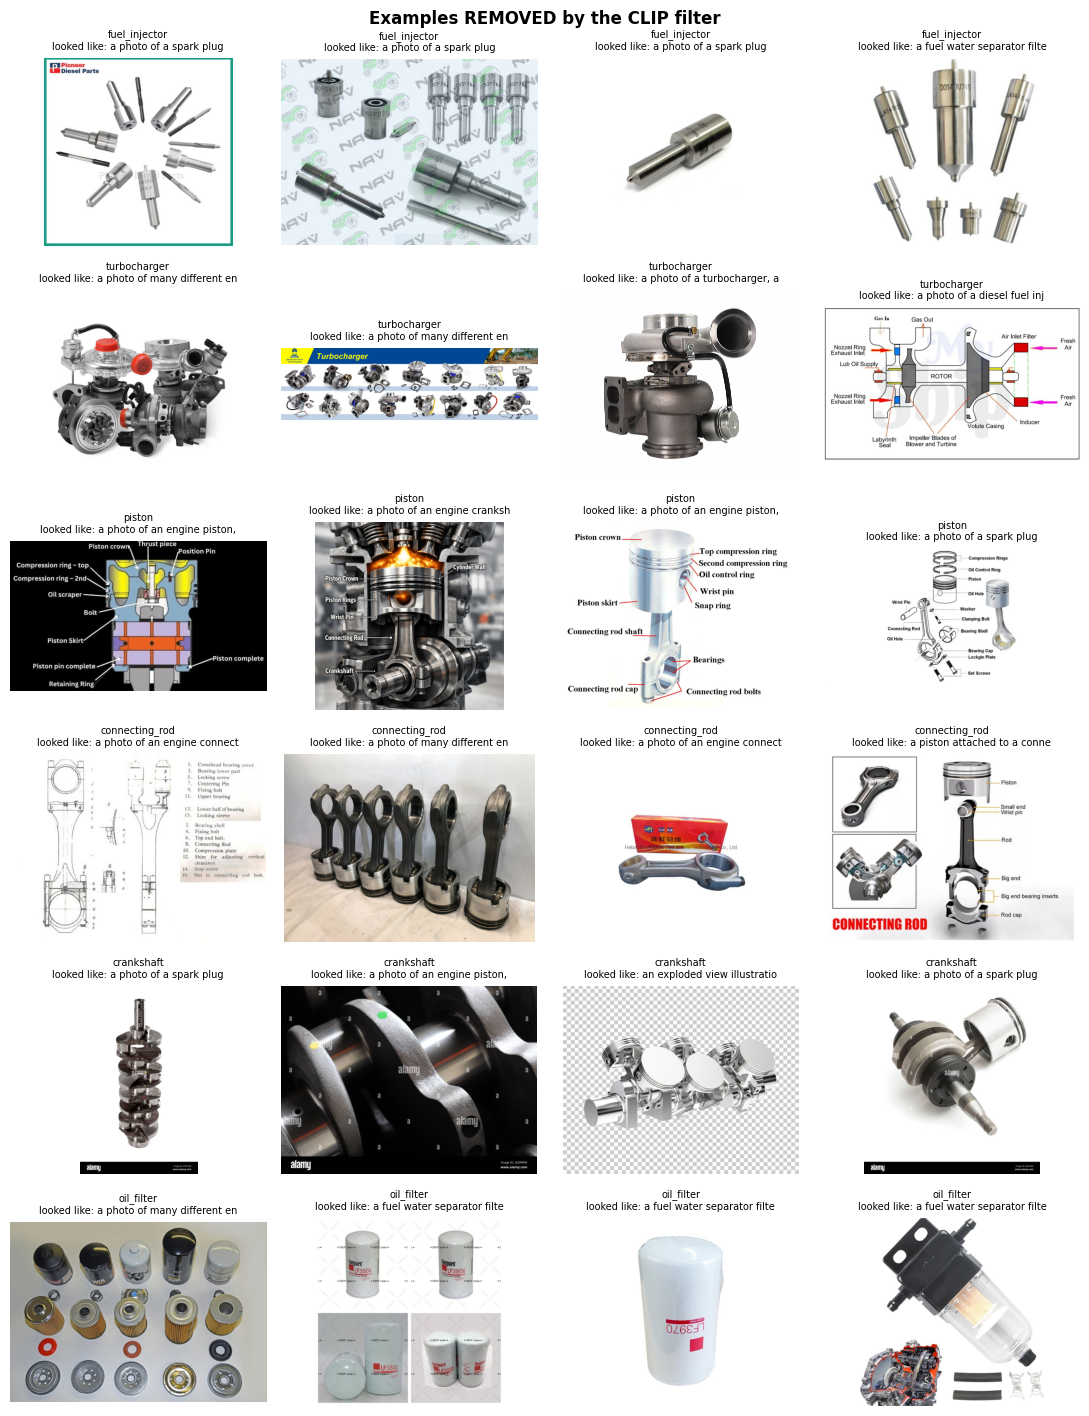

In [34]:
import imagehash
from transformers import CLIPModel, CLIPProcessor

# --- 1. near-duplicate removal (across all classes) ---
all_files = [(cls, p) for cls in CLASSES for p in sorted(glob.glob(os.path.join(RAW_DIR, cls, "*.jpg")))]
kept_hashes, dup_removed = [], {c: 0 for c in CLASSES}
for cls, p in all_files:
    try:
        h = imagehash.phash(Image.open(p).convert("RGB")).hash.flatten()
    except Exception:
        os.remove(p); dup_removed[cls] += 1; continue
    if kept_hashes and (np.array(kept_hashes) != h).sum(1).min() <= 6:
        os.remove(p); dup_removed[cls] += 1
    else:
        kept_hashes.append(h)
print("near-duplicates removed:", dup_removed)

# --- 2. CLIP relevance filter ---
CLIP_PROMPTS = {
    "fuel_injector":  "a photo of a diesel fuel injector, a single engine part",
    "turbocharger":   "a photo of a turbocharger, a single engine part",
    "piston":         "a photo of an engine piston, a single engine part",
    "connecting_rod": "a photo of an engine connecting rod, a single engine part",
    "crankshaft":     "a photo of an engine crankshaft, a single engine part",
    "oil_filter":     "a photo of an oil filter, a single engine part",
}
DISTRACTORS = ["a photo of a soldier", "a photo of people", "a logo or text", "a technical drawing or diagram",
               "a labeled diagram with text callouts", "an exploded view illustration", "an infographic",
               "a photo of a car", "a photo of a boat or ship", "a photo of a complete engine", "a photo of an engine bay",
               "a screenshot of a website", "a photo of tools", "a photo of a spark plug",
               "a fuel water separator filter", "a piston attached to a connecting rod", "a photo of many different engine parts"]
class_list = list(CLASSES)
texts = [CLIP_PROMPTS[c] for c in class_list] + DISTRACTORS

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

rejected_examples = {c: [] for c in class_list}
clip_report = {}
for ci, cls in enumerate(class_list):
    files = sorted(glob.glob(os.path.join(RAW_DIR, cls, "*.jpg")))
    kept = 0
    for i in range(0, len(files), 32):
        batch = files[i:i + 32]
        ims = [Image.open(f).convert("RGB") for f in batch]
        inputs = clip_proc(text=texts, images=ims, return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            probs = clip_model(**inputs).logits_per_image.softmax(-1).cpu().numpy()
        for f, pr in zip(batch, probs):
            if pr.argmax() == ci and pr[ci] >= MIN_CLIP_PROB:
                kept += 1
            else:
                if len(rejected_examples[cls]) < 4:
                    rejected_examples[cls].append((Image.open(f).convert("RGB").copy(), texts[pr.argmax()]))
                os.remove(f)
    clip_report[cls] = {"kept": kept, "removed": len(files) - kept}
display(pd.DataFrame(clip_report).T)
too_small = [c for c, v in clip_report.items() if v["kept"] < 80]
if too_small:
    print(f"⚠️  Few images left for {too_small}. Lower MIN_CLIP_PROB in section 2 or add search queries for these parts.")

# show what was thrown away, so you can check the filter is sensible
fig, axes = plt.subplots(len(class_list), 4, figsize=(11, 2.4 * len(class_list)))
for r_, cls in enumerate(class_list):
    for c_ in range(4):
        ax = axes[r_, c_]; ax.axis("off")
        if c_ < len(rejected_examples[cls]):
            im, why = rejected_examples[cls][c_]
            ax.imshow(im); ax.set_title(f"{cls}\nlooked like: {why[:28]}", fontsize=7)
plt.suptitle("Examples REMOVED by the CLIP filter", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/clip_rejected.png", dpi=110); plt.show()

del clip_model
if device.type == "cuda":
    torch.cuda.empty_cache()

### 3.2 Train / validation / test split
A fixed random seed makes the split reproducible. The **test** set is never used for training or for choosing the best epoch, so it gives an honest final score.

,train,val,test,total
fuel_injector,110,23,25,158
turbocharger,125,27,28,180
piston,108,23,24,155
connecting_rod,115,24,26,165
crankshaft,166,35,37,238
oil_filter,143,30,32,205


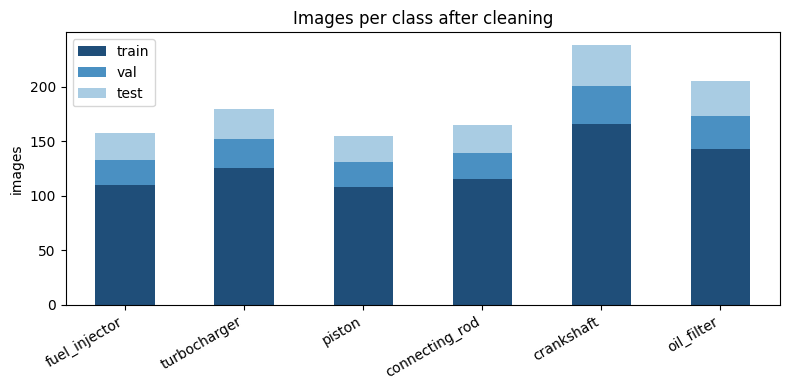

In [35]:
if os.path.exists(DATA_DIR):
    shutil.rmtree(DATA_DIR)
rng = random.Random(42)
counts = {}
for cls in CLASSES:
    files = sorted(glob.glob(os.path.join(RAW_DIR, cls, "*.jpg")))
    rng.shuffle(files)
    n = len(files)
    n_tr, n_va = int(SPLIT[0] * n), int(SPLIT[1] * n)
    parts = {"train": files[:n_tr], "val": files[n_tr:n_tr + n_va], "test": files[n_tr + n_va:]}
    for split, fl in parts.items():
        dst = os.path.join(DATA_DIR, split, cls)
        os.makedirs(dst, exist_ok=True)
        for f in fl:
            shutil.copy(f, dst)
    counts[cls] = {k: len(v) for k, v in parts.items()}

count_df = pd.DataFrame(counts).T
too_few = count_df.index[count_df.min(axis=1) < 3].tolist()
assert not too_few, f"Not enough images for: {too_few}. Add more images to these classes and re-run section 3."
count_df["total"] = count_df.sum(axis=1)
display(count_df)

ax = count_df[["train", "val", "test"]].plot(kind="bar", stacked=True, figsize=(8, 4), color=["#1f4e79", "#4a90c2", "#a9cce3"])
ax.set_title("Images per class after cleaning"); ax.set_ylabel("images"); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/class_counts.png", dpi=150); plt.show()

### 3.3 Look at the data

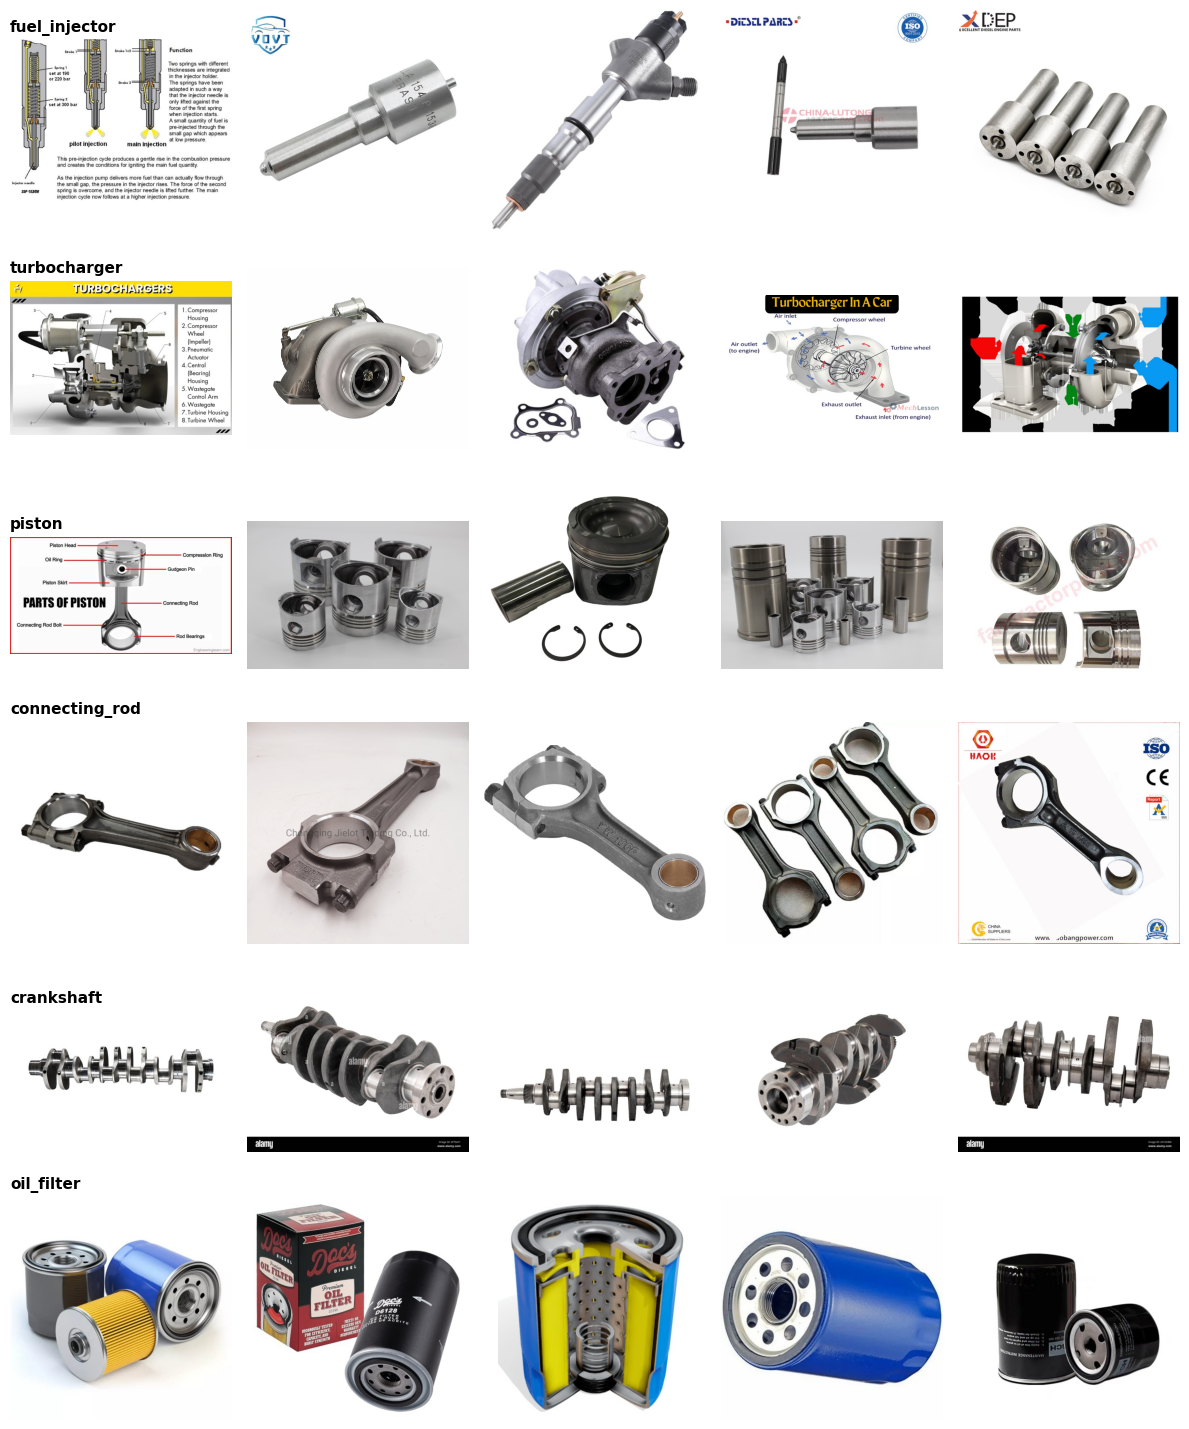

In [36]:
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(12, 2.4 * len(CLASSES)))
for i, cls in enumerate(CLASSES):
    files = sorted(glob.glob(os.path.join(DATA_DIR, "train", cls, "*.jpg")))[:5]
    for j in range(5):
        ax = axes[i, j]; ax.axis("off")
        if j < len(files):
            ax.imshow(Image.open(files[j]))
        if j == 0:
            ax.set_title(cls, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/sample_images.png", dpi=120); plt.show()

> ✏️ **Check this grid.** If a class has obviously wrong images (logos, diagrams, unrelated products), delete them from `raw_images/<class>` and re-run sections 3.1–3.3. A cleaner dataset matters more than any hyperparameter.

## 4. Preprocessing
AlexNet was pretrained on ImageNet, so every image is resized to **224×224** and normalized with the ImageNet channel means and standard deviations. The **augmented** pipeline adds random crops, flips, rotations and color jitter to the *training* images only — this simulates the varied lighting and angles of photos taken in an engine room.

Classes: ['connecting_rod', 'crankshaft', 'fuel_injector', 'oil_filter', 'piston', 'turbocharger']


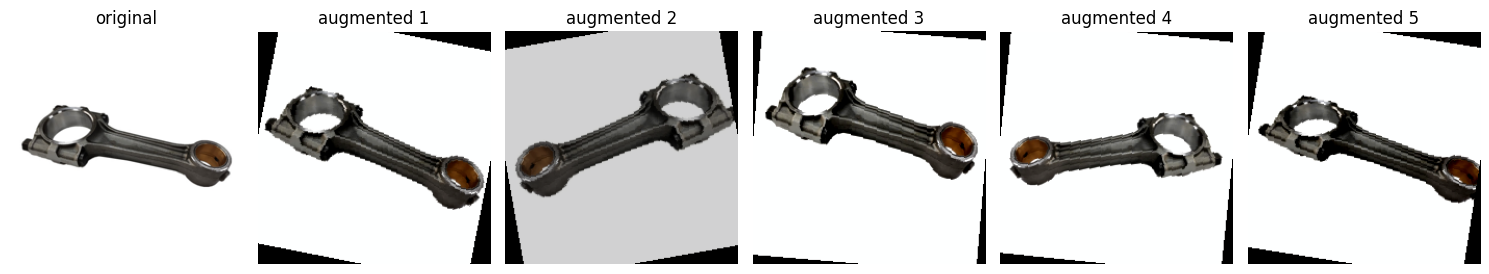

In [37]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf_aug = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
train_tf_plain = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = train_tf_plain

val_ds  = datasets.ImageFolder(os.path.join(DATA_DIR, "val"),  transform=eval_tf)
test_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=eval_tf)
CLASS_NAMES = val_ds.classes
NUM_CLASSES = len(CLASS_NAMES)
print("Classes:", CLASS_NAMES)

# show what augmentation does to one image
sample_path = sorted(glob.glob(os.path.join(DATA_DIR, "train", CLASS_NAMES[0], "*.jpg")))[0]
img = Image.open(sample_path).convert("RGB")
def denorm(t):
    return (t.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(img.resize((IMG_SIZE, IMG_SIZE))); axes[0].set_title("original")
for k in range(1, 6):
    axes[k].imshow(denorm(train_tf_aug(img))); axes[k].set_title(f"augmented {k}")
for a in axes: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/augmentation_examples.png", dpi=120); plt.show()

## 5. Models
**AlexNet** (Krizhevsky et al., 2012): 5 convolutional layers (with ReLU, max-pooling and local response normalization replaced by modern defaults in torchvision) followed by 3 fully connected layers with dropout. We load ImageNet-pretrained weights (**transfer learning**) and replace the final 1000-class layer with a 6-class layer.

**ResNet18** (He et al., 2015) is used as the comparison model: deeper (18 layers), but with skip connections and far fewer parameters.

In [38]:
def build_model(name, num_classes=NUM_CLASSES):
    if name == "alexnet":
        m = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, num_classes)
    elif name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    else:
        raise ValueError(name)
    return m.to(device)

alex = build_model("alexnet")
print(alex)
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"\nAlexNet parameters:  {n_params(alex)/1e6:.1f} M")
print(f"ResNet18 parameters: {n_params(build_model('resnet18'))/1e6:.1f} M")
del alex

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

## 6. Training & evaluation functions
- **Loss:** cross-entropy (standard for multi-class classification)
- **Optimizer:** Adam
- **Model selection:** we keep the weights from the epoch with the best **validation** accuracy, then score them once on the **test** set
- Every epoch's train/val loss and accuracy is logged to Weights & Biases

In [39]:
def make_loaders(batch_size, augment):
    train_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "train"),
                                    transform=train_tf_aug if augment else train_tf_plain)
    workers = 2 if device.type == "cuda" else 0
    return (DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=workers, pin_memory=True),
            DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=workers),
            DataLoader(test_ds,  batch_size=64, shuffle=False, num_workers=workers))

def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            preds = out.argmax(1)
            total_loss += loss.item() * x.size(0)
            correct += (preds == y).sum().item()
            n += x.size(0)
            all_preds += preds.cpu().tolist(); all_labels += y.cpu().tolist()
    return total_loss / n, correct / n, all_preds, all_labels

def run_experiment(run_name, model_name="alexnet", batch_size=32, lr=1e-4, augment=True,
                   epochs=EPOCHS, group=None):
    set_seed(42)
    cfg = dict(model=model_name, batch_size=batch_size, learning_rate=lr, augment=augment,
               epochs=epochs, optimizer="Adam", scheduler="cosine", label_smoothing=0.1, img_size=IMG_SIZE, classes=CLASS_NAMES)
    run = wandb.init(project=WANDB_PROJECT, name=run_name, group=group, config=cfg,
                     mode=WANDB_MODE)
    train_loader, val_loader, test_loader = make_loaders(batch_size, augment)
    model = build_model(model_name)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)   # softer targets: less over-confidence on noisy web labels
    eval_criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)  # lowers LR smoothly to 0

    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best_acc, best_state, best_epoch = -1, None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        tl, ta, _, _ = run_epoch(model, train_loader, criterion, optimizer)
        scheduler.step()
        vl, va, _, _ = run_epoch(model, val_loader, eval_criterion)
        for k, v in zip(hist, [tl, ta, vl, va]):
            hist[k].append(v)
        wandb.log({"epoch": ep, "train_loss": tl, "train_acc": ta, "val_loss": vl, "val_acc": va})
        if va > best_acc:
            best_acc, best_state, best_epoch = va, copy.deepcopy(model.state_dict()), ep
        print(f"[{run_name}] epoch {ep:2d}/{epochs}  train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

    model.load_state_dict(best_state)
    weights_path = f"{MODEL_DIR}/{run_name}.pt"
    torch.save(best_state, weights_path)
    test_loss, test_acc, preds, labels = run_epoch(model, test_loader, eval_criterion)
    minutes = (time.time() - t0) / 60

    # confusion matrix: to W&B and to a PNG for the poster/website
    wandb.log({"test_acc": test_acc, "test_loss": test_loss, "best_val_acc": best_acc,
               "confusion_matrix": wandb.plot.confusion_matrix(y_true=labels, preds=preds, class_names=CLASS_NAMES)})
    cm = confusion_matrix(labels, preds, labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=35)
    ax.set_title(f"{run_name} — test accuracy {test_acc:.1%}")
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/cm_{run_name}.png", dpi=150); plt.close(fig)
    run.finish()

    print(f"✅ {run_name}: best val acc {best_acc:.3f} (epoch {best_epoch}), TEST acc {test_acc:.3f}, {minutes:.1f} min")
    return dict(run=run_name, group=group, model=model_name, batch_size=batch_size, lr=lr,
                augment=augment, best_val_acc=best_acc, best_epoch=best_epoch,
                test_acc=test_acc, test_loss=test_loss, minutes=minutes,
                history=hist, preds=preds, labels=labels, weights=weights_path)

## 7. Log in to Weights & Biases
Paste your API key from https://wandb.ai/authorize when asked. (No account? set `WANDB_MODE = "disabled"` in section 2 — everything else still works.)

In [40]:
if WANDB_MODE != "disabled":
    wandb.login()

## 8. Experiments
Each experiment changes **one** setting relative to the **baseline** (AlexNet, batch 32, learning rate 1e-4, augmentation on), so any difference can be attributed to that setting.

| Run | Model | Batch | LR | Augment | Tests |
|---|---|---|---|---|---|
| `baseline` | AlexNet | 32 | 1e-4 | ✅ | reference |
| `bs16` | AlexNet | **16** | 1e-4 | ✅ | batch size |
| `bs64` | AlexNet | **64** | 1e-4 | ✅ | batch size |
| `lr1e-3` | AlexNet | 32 | **1e-3** | ✅ | learning rate |
| `lr1e-5` | AlexNet | 32 | **1e-5** | ✅ | learning rate |
| `no_aug` | AlexNet | 32 | 1e-4 | **❌** | augmentation |
| `resnet18` | **ResNet18** | 32 | 1e-4 | ✅ | architecture |
| `resnet50` | **ResNet50** | 32 | 1e-4 | ✅ | architecture (candidate for the real tool) |

All runs use cross-entropy with label smoothing 0.1, Adam, and a cosine learning-rate schedule.

In [41]:
EXPERIMENTS = [
    dict(run_name="baseline", group="baseline"),
    dict(run_name="bs16",     group="batch_size",   batch_size=16),
    dict(run_name="bs64",     group="batch_size",   batch_size=64),
    dict(run_name="lr1e-3",   group="learning_rate", lr=1e-3),
    dict(run_name="lr1e-5",   group="learning_rate", lr=1e-5),
    dict(run_name="no_aug",   group="augmentation", augment=False),
    dict(run_name="resnet18", group="architecture", model_name="resnet18"),
    dict(run_name="resnet50", group="architecture", model_name="resnet50"),
]
results = []
for exp in EXPERIMENTS:
    results.append(run_experiment(**exp))

[baseline] epoch  1/15  train loss 1.186 acc 0.649 | val loss 0.702 acc 0.778
[baseline] epoch  2/15  train loss 0.772 acc 0.862 | val loss 0.596 acc 0.821
[baseline] epoch  3/15  train loss 0.651 acc 0.928 | val loss 0.544 acc 0.833
[baseline] epoch  4/15  train loss 0.579 acc 0.966 | val loss 0.572 acc 0.846
[baseline] epoch  5/15  train loss 0.562 acc 0.973 | val loss 0.545 acc 0.852
[baseline] epoch  6/15  train loss 0.544 acc 0.978 | val loss 0.525 acc 0.846
[baseline] epoch  7/15  train loss 0.530 acc 0.982 | val loss 0.503 acc 0.864
[baseline] epoch  8/15  train loss 0.519 acc 0.982 | val loss 0.493 acc 0.877
[baseline] epoch  9/15  train loss 0.503 acc 0.992 | val loss 0.478 acc 0.889
[baseline] epoch 10/15  train loss 0.491 acc 0.999 | val loss 0.484 acc 0.895
[baseline] epoch 11/15  train loss 0.488 acc 0.997 | val loss 0.479 acc 0.901
[baseline] epoch 12/15  train loss 0.480 acc 0.999 | val loss 0.467 acc 0.883
[baseline] epoch 13/15  train loss 0.481 acc 0.996 | val loss 0.

best_val_acc,▁
epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
test_acc,▁
test_loss,▁
train_acc,▁▅▇▇▇██████████
train_loss,█▄▃▂▂▂▂▁▁▁▁▁▁▁▁
val_acc,▁▃▄▅▅▅▆▇▇██▇▇▇▇
val_loss,█▅▃▄▃▃▂▂▁▂▁▁▁▁▁
best_val_acc,0.90123
epoch,15
test_acc,0.88953


✅ baseline: best val acc 0.901 (epoch 11), TEST acc 0.890, 4.2 min


[bs16] epoch  1/15  train loss 1.154 acc 0.686 | val loss 0.681 acc 0.784
[bs16] epoch  2/15  train loss 0.767 acc 0.862 | val loss 0.636 acc 0.796
[bs16] epoch  3/15  train loss 0.648 acc 0.935 | val loss 0.466 acc 0.870
[bs16] epoch  4/15  train loss 0.568 acc 0.958 | val loss 0.522 acc 0.852
[bs16] epoch  5/15  train loss 0.555 acc 0.974 | val loss 0.506 acc 0.889
[bs16] epoch  6/15  train loss 0.527 acc 0.975 | val loss 0.464 acc 0.889
[bs16] epoch  7/15  train loss 0.508 acc 0.987 | val loss 0.485 acc 0.870
[bs16] epoch  8/15  train loss 0.503 acc 0.986 | val loss 0.442 acc 0.901
[bs16] epoch  9/15  train loss 0.484 acc 0.996 | val loss 0.491 acc 0.889
[bs16] epoch 10/15  train loss 0.482 acc 0.993 | val loss 0.491 acc 0.901
[bs16] epoch 11/15  train loss 0.476 acc 0.997 | val loss 0.452 acc 0.907
[bs16] epoch 12/15  train loss 0.476 acc 0.996 | val loss 0.458 acc 0.907
[bs16] epoch 13/15  train loss 0.468 acc 1.000 | val loss 0.459 acc 0.907
[bs16] epoch 14/15  train loss 0.473 a

best_val_acc,▁
epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
test_acc,▁
test_loss,▁
train_acc,▁▅▇▇▇▇█████████
train_loss,█▄▃▂▂▂▁▁▁▁▁▁▁▁▁
val_acc,▁▂▆▅▇▇▆█▇██████
val_loss,█▇▂▃▃▂▂▁▂▂▁▁▁▁▁
best_val_acc,0.90741
epoch,15
test_acc,0.90116


✅ bs16: best val acc 0.907 (epoch 11), TEST acc 0.901, 4.1 min


... (14 outputs left out)

✅ resnet18: best val acc 0.951 (epoch 5), TEST acc 0.953, 4.1 min


[resnet50] epoch  1/15  train loss 1.475 acc 0.631 | val loss 0.832 acc 0.901
[resnet50] epoch  2/15  train loss 0.702 acc 0.939 | val loss 0.261 acc 0.944
[resnet50] epoch  3/15  train loss 0.528 acc 0.967 | val loss 0.288 acc 0.944
[resnet50] epoch  4/15  train loss 0.493 acc 0.979 | val loss 0.231 acc 0.957
[resnet50] epoch  5/15  train loss 0.484 acc 0.987 | val loss 0.233 acc 0.969
[resnet50] epoch  6/15  train loss 0.461 acc 0.991 | val loss 0.210 acc 0.969
[resnet50] epoch  7/15  train loss 0.458 acc 0.992 | val loss 0.201 acc 0.988
[resnet50] epoch  8/15  train loss 0.456 acc 0.995 | val loss 0.183 acc 0.975
[resnet50] epoch  9/15  train loss 0.449 acc 0.996 | val loss 0.182 acc 0.981
[resnet50] epoch 10/15  train loss 0.442 acc 0.999 | val loss 0.183 acc 0.969
[resnet50] epoch 11/15  train loss 0.451 acc 0.999 | val loss 0.174 acc 0.975
[resnet50] epoch 12/15  train loss 0.440 acc 0.997 | val loss 0.174 acc 0.975
[resnet50] epoch 13/15  train loss 0.440 acc 1.000 | val loss 0.

best_val_acc,▁
epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
test_acc,▁
test_loss,▁
train_acc,▁▇▇████████████
train_loss,█▃▂▁▁▁▁▁▁▁▁▁▁▁▁
val_acc,▁▄▄▆▇▇█▇█▇▇▇▇▇▇
val_loss,█▂▂▂▂▁▁▁▁▁▁▁▁▁▁
best_val_acc,0.98765
epoch,15
test_acc,0.98837


✅ resnet50: best val acc 0.988 (epoch 7), TEST acc 0.988, 4.6 min


## 9. Results

In [42]:
summary = pd.DataFrame([{k: r[k] for k in ["run", "group", "model", "batch_size", "lr", "augment",
                                           "best_val_acc", "best_epoch", "test_acc", "minutes"]} for r in results])
summary_display = summary.copy()
for c in ["best_val_acc", "test_acc"]:
    summary_display[c] = (summary_display[c] * 100).round(1).astype(str) + "%"
summary_display["minutes"] = summary_display["minutes"].round(1)
display(summary_display)
summary.to_csv(f"{FIG_DIR}/results_summary.csv", index=False)
with open(f"{FIG_DIR}/results_full.json", "w") as f:
    json.dump([{k: v for k, v in r.items() if k not in ("preds", "labels")} for r in results], f, indent=2)

,run,group,model,batch_size,lr,augment,best_val_acc,best_epoch,test_acc,minutes
0,baseline,baseline,alexnet,32,0.00010,True,90.1%,11,89.0%,4.2
1,bs16,batch_size,alexnet,16,0.00010,True,90.7%,11,90.1%,4.1
2,bs64,batch_size,alexnet,64,0.00010,True,88.9%,6,87.2%,4.1
3,lr1e-3,learning_rate,alexnet,32,0.00100,True,22.2%,1,20.9%,4.1
4,lr1e-5,learning_rate,alexnet,32,0.00001,True,79.0%,12,84.3%,4.1
5,no_aug,augmentation,alexnet,32,0.00010,False,89.5%,7,88.4%,3.6
6,resnet18,architecture,resnet18,32,0.00010,True,95.1%,5,95.3%,4.1
7,resnet50,architecture,resnet50,32,0.00010,True,98.8%,7,98.8%,4.6


### 9.1 Training vs. validation curves (baseline)

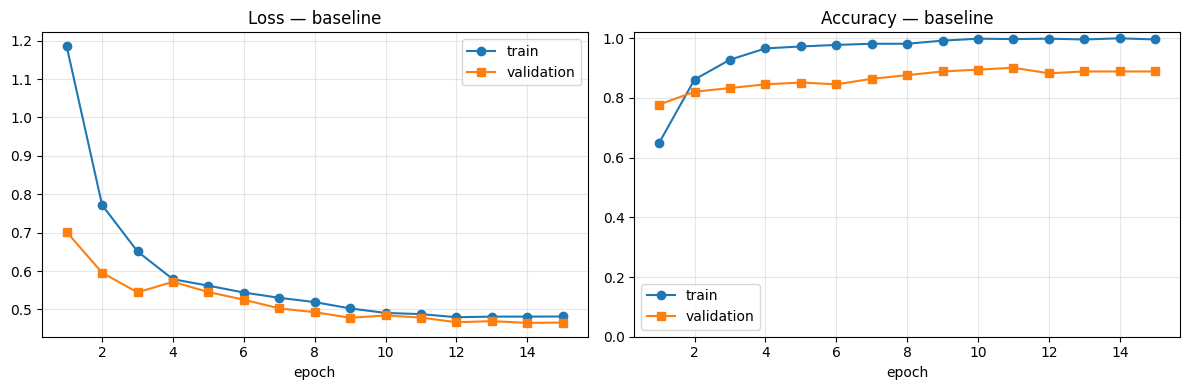

In [43]:
def plot_curves(r, fname):
    h = r["history"]; ep = range(1, len(h["train_loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    a1.plot(ep, h["train_loss"], "o-", label="train"); a1.plot(ep, h["val_loss"], "s-", label="validation")
    a1.set_title(f"Loss — {r['run']}"); a1.set_xlabel("epoch"); a1.legend()
    a2.plot(ep, h["train_acc"], "o-", label="train"); a2.plot(ep, h["val_acc"], "s-", label="validation")
    a2.set_title(f"Accuracy — {r['run']}"); a2.set_xlabel("epoch"); a2.set_ylim(0, 1.02); a2.legend()
    for a in (a1, a2): a.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{fname}", dpi=150); plt.show()

by_name = {r["run"]: r for r in results}
plot_curves(by_name["baseline"], "curves_baseline.png")

### 9.2 Experiment comparisons (validation accuracy per epoch)

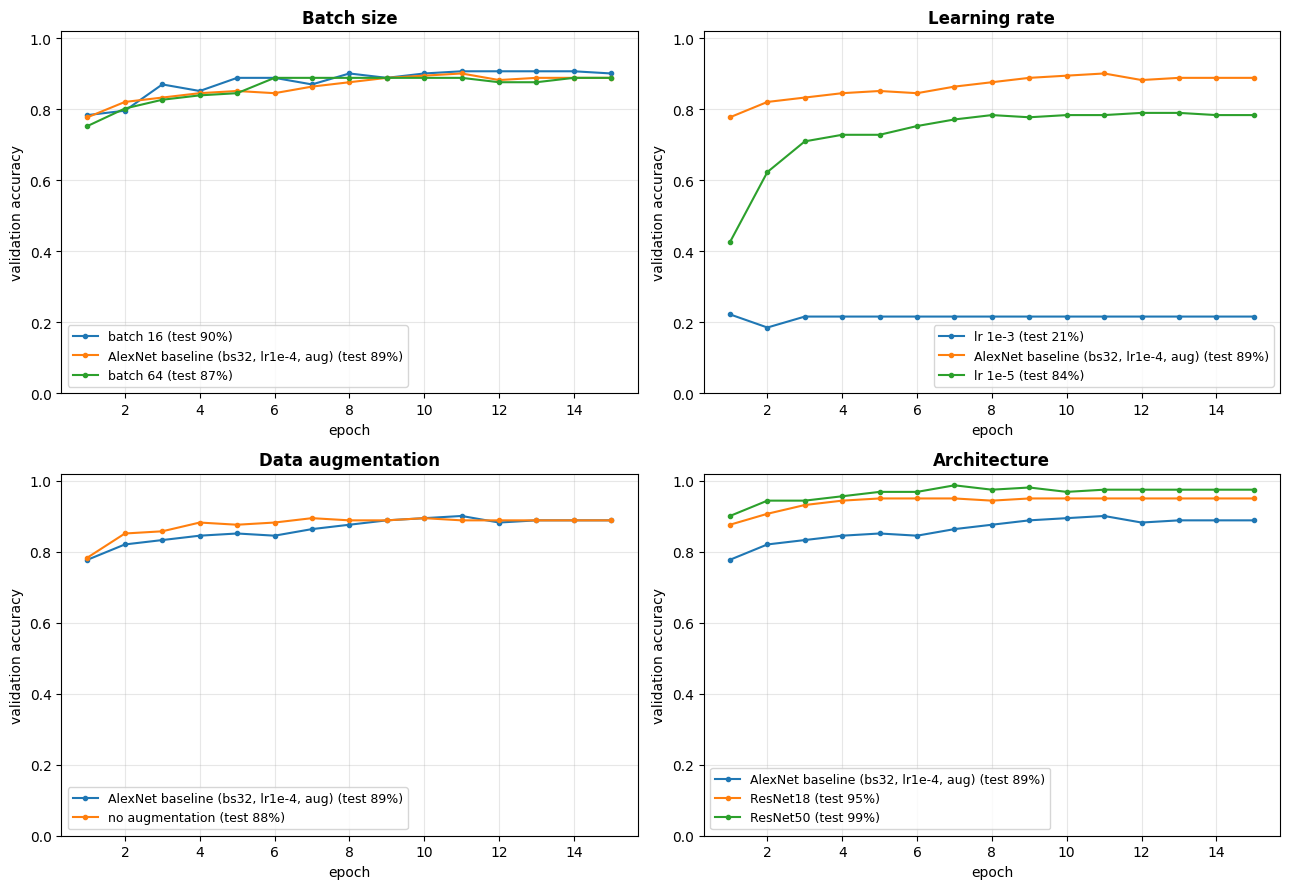

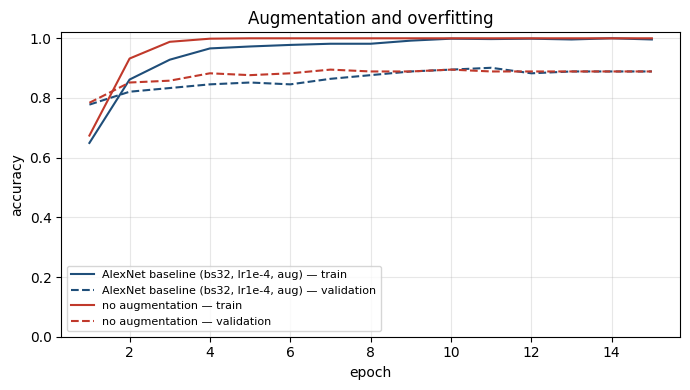

In [44]:
COMPARISONS = {
    "Batch size":        ["bs16", "baseline", "bs64"],
    "Learning rate":     ["lr1e-3", "baseline", "lr1e-5"],
    "Data augmentation": ["baseline", "no_aug"],
    "Architecture":      ["baseline", "resnet18", "resnet50"],
}
LABELS = {"baseline": "AlexNet baseline (bs32, lr1e-4, aug)", "bs16": "batch 16", "bs64": "batch 64",
          "lr1e-3": "lr 1e-3", "lr1e-5": "lr 1e-5", "no_aug": "no augmentation", "resnet18": "ResNet18",
          "resnet50": "ResNet50"}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (title, runs) in zip(axes.flat, COMPARISONS.items()):
    for rn in runs:
        h = by_name[rn]["history"]
        ax.plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], "o-", ms=3,
                label=f"{LABELS[rn]} (test {by_name[rn]['test_acc']:.0%})")
    ax.set_title(title, fontweight="bold"); ax.set_xlabel("epoch"); ax.set_ylabel("validation accuracy")
    ax.set_ylim(0, 1.02); ax.grid(alpha=.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/experiment_comparisons.png", dpi=150); plt.show()

# overfitting check: train vs val accuracy gap with/without augmentation
fig, ax = plt.subplots(figsize=(7, 4))
for rn, c in [("baseline", "#1f4e79"), ("no_aug", "#c0392b")]:
    h = by_name[rn]["history"]; ep = range(1, len(h["train_acc"]) + 1)
    ax.plot(ep, h["train_acc"], "-", color=c, label=f"{LABELS[rn]} — train")
    ax.plot(ep, h["val_acc"], "--", color=c, label=f"{LABELS[rn]} — validation")
ax.set_title("Augmentation and overfitting"); ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1.02)
ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/augmentation_gap.png", dpi=150); plt.show()

### 9.3 Test accuracy of every run

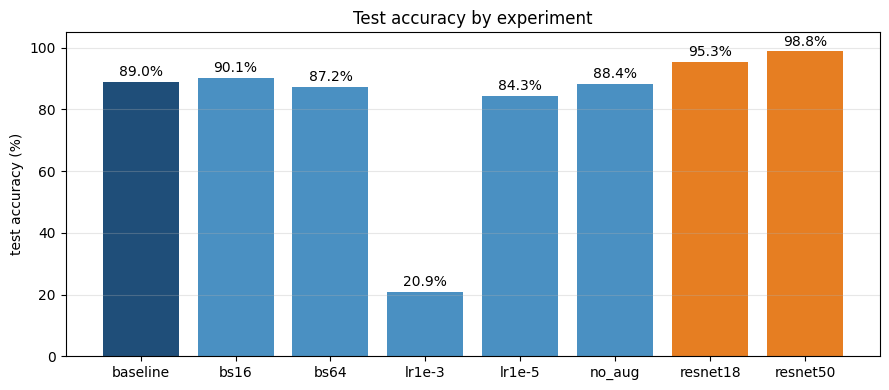

In [45]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#1f4e79" if g == "baseline" else "#4a90c2" if m == "alexnet" else "#e67e22"
          for g, m in zip(summary["group"], summary["model"])]
bars = ax.bar(summary["run"], summary["test_acc"] * 100, color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=2)
ax.set_ylabel("test accuracy (%)"); ax.set_ylim(0, 105); ax.set_title("Test accuracy by experiment")
ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/test_accuracy_bar.png", dpi=150); plt.show()

### 9.4 Best model: confusion matrix & per-class report

Best run overall (by validation accuracy): resnet50  → test accuracy 98.8%
Best AlexNet run: bs16  → test accuracy 90.1%

                precision    recall  f1-score   support

connecting_rod      1.000     1.000     1.000        26
    crankshaft      1.000     0.946     0.972        37
 fuel_injector      1.000     1.000     1.000        25
    oil_filter      1.000     1.000     1.000        32
        piston      1.000     1.000     1.000        24
  turbocharger      0.933     1.000     0.966        28

      accuracy                          0.988       172
     macro avg      0.989     0.991     0.990       172
  weighted avg      0.989     0.988     0.988       172



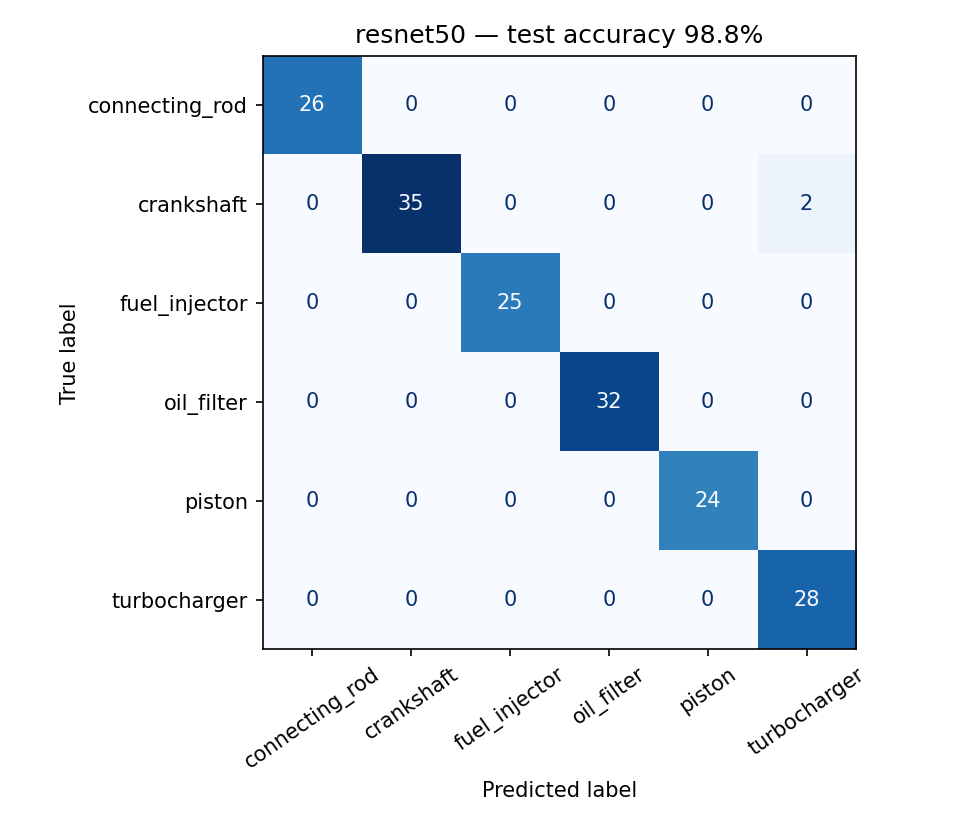

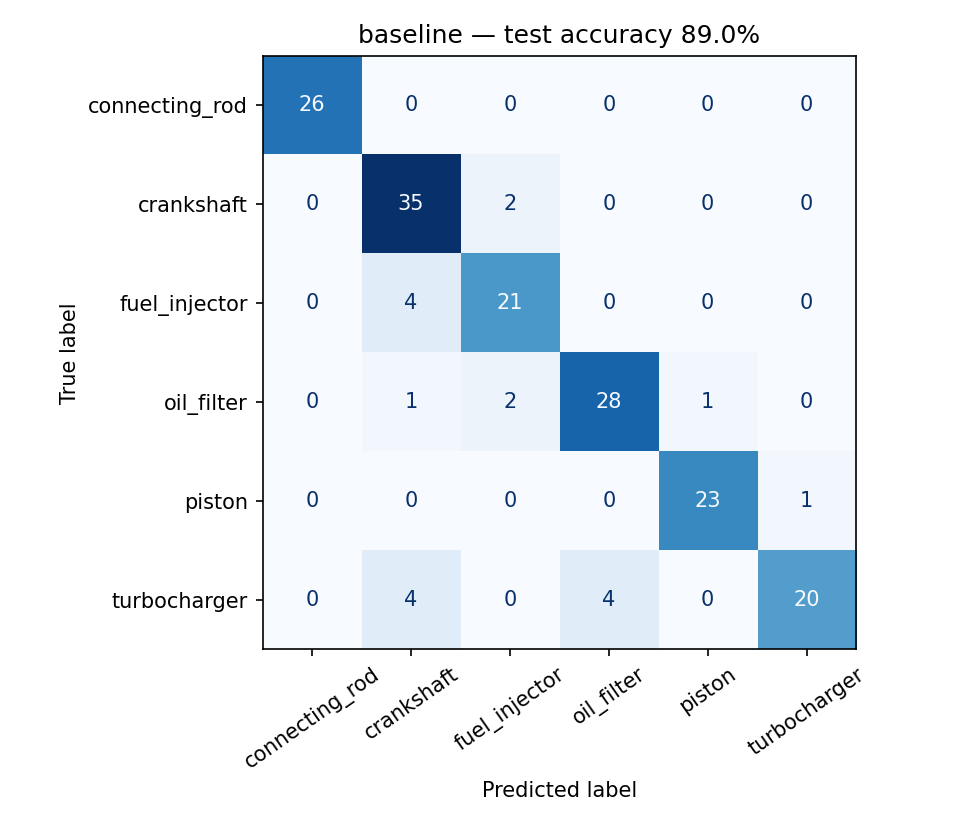

In [46]:
best = max(results, key=lambda r: r["best_val_acc"])   # chosen on validation, not test
best_alex = max([r for r in results if r["model"] == "alexnet"], key=lambda r: r["best_val_acc"])
print(f"Best run overall (by validation accuracy): {best['run']}  → test accuracy {best['test_acc']:.1%}")
print(f"Best AlexNet run: {best_alex['run']}  → test accuracy {best_alex['test_acc']:.1%}\n")
print(classification_report(best["labels"], best["preds"], target_names=CLASS_NAMES, digits=3, zero_division=0))
display(Image.open(f"{FIG_DIR}/cm_{best['run']}.png"))
if best["run"] != "baseline":
    display(Image.open(f"{FIG_DIR}/cm_baseline.png"))

### 9.5 Where does the model get it wrong?

2 of 172 test images misclassified


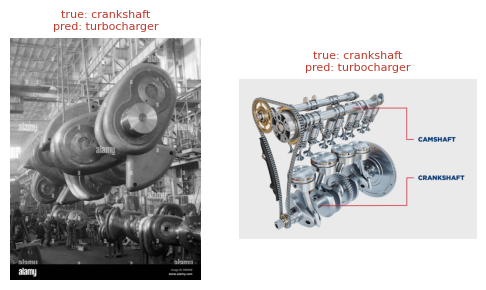

In [47]:
test_paths = [p for p, _ in test_ds.samples]
wrong = [(p, CLASS_NAMES[t], CLASS_NAMES[pr]) for p, t, pr in zip(test_paths, best["labels"], best["preds"]) if t != pr]
print(f"{len(wrong)} of {len(test_paths)} test images misclassified")
if wrong:
    k = min(8, len(wrong))
    fig, axes = plt.subplots(1, k, figsize=(2.6 * k, 3))
    axes = np.atleast_1d(axes)
    for ax, (p, t, pr) in zip(axes, wrong[:k]):
        ax.imshow(Image.open(p).convert("RGB")); ax.axis("off")
        ax.set_title(f"true: {t}\npred: {pr}", fontsize=8, color="#c0392b")
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/misclassified.png", dpi=120); plt.show()

## 10. Try it on a new photo
Upload any photo of an engine part and the best model predicts what it is, with confidence for each class.

Saving images.jpeg to images.jpeg


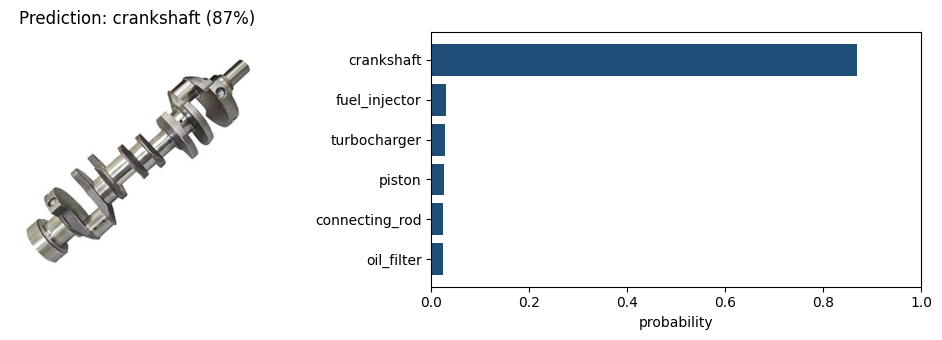

In [48]:
best_model = build_model(best["model"])
best_model.load_state_dict(torch.load(best["weights"], map_location=device))
best_model.eval()

CONFIDENCE_THRESHOLD = 0.60   # below this the tool says "not sure" instead of guessing

def predict(path):
    img = Image.open(path).convert("RGB")
    with torch.no_grad():
        probs = torch.softmax(best_model(eval_tf(img).unsqueeze(0).to(device)), 1)[0].cpu().numpy()
    order = probs.argsort()[::-1]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={"width_ratios": [1, 1.4]})
    top = probs[order[0]]
    label = CLASS_NAMES[order[0]] if top >= CONFIDENCE_THRESHOLD else f"not sure (best guess {CLASS_NAMES[order[0]]})"
    a1.imshow(img); a1.axis("off"); a1.set_title(f"Prediction: {label} ({top:.0%})")
    a2.barh([CLASS_NAMES[i] for i in order][::-1], probs[order][::-1], color="#1f4e79")
    a2.set_xlim(0, 1); a2.set_xlabel("probability")
    plt.tight_layout(); plt.show()

try:
    from google.colab import files
    uploaded = files.upload()
    for name in uploaded:
        predict(name)
except Exception:
    # not in Colab, or no upload: demo on a test image instead
    predict(test_paths[0])

## 11. Save everything
Downloads a zip with every figure (for the website and poster), the results table, and the best model weights.

In [49]:
shutil.copy(best["weights"], f"{FIG_DIR}/best_model_{best['run']}.pt")
shutil.make_archive(os.path.join(BASE, "partsight_outputs"), "zip", FIG_DIR)
print("Saved:", os.path.join(BASE, "partsight_outputs.zip"))
try:
    from google.colab import files
    files.download(os.path.join(BASE, "partsight_outputs.zip"))
except Exception:
    pass

Saved: /content/partsight_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Discussion
**Results (test set, 172 held-out photos):** ResNet50 98.8% · ResNet18 95.3% · AlexNet batch 16 90.1% · AlexNet baseline 89.0% · no augmentation 88.4% · batch 64 87.2% · LR 1e-5 84.3% · LR 1e-3 20.9%.

**Learning rate mattered most.** At 1e-3 the large updates wiped out the pretrained ImageNet weights and accuracy collapsed to 20.9%, about the same as always guessing the most common part. At 1e-5 the model learned too slowly (84.3% after 15 epochs, still rising). 1e-4 was the best of the three.

**Batch size had a small effect.** Batch 16 (90.1%) edged out 32 (89.0%) and 64 (87.2%). Smaller batches give more weight updates per epoch, and their noisier gradients act as mild regularization. The spread is only about 5 test photos, so this is a weak effect.

**Data augmentation slowed memorization.** Without augmentation, training accuracy reached 100% by epoch 4 while validation accuracy stalled (`augmentation_gap.png`). The test gain was small (89.0% vs 88.4%), because label smoothing and the pretrained weights already limit overfitting.

**AlexNet vs. ResNet.** ResNet18 (95.3%) and ResNet50 (98.8%) clearly beat AlexNet in about the same training time (~4 minutes per run). Deeper networks with skip connections and stronger pretrained features generalize better, even though ResNet18 has about 5× fewer parameters than AlexNet.

**Errors.** ResNet50 made 2 mistakes out of 172: both crankshafts in busy scenes (a factory floor and a whole-engine cutaway) predicted as turbochargers. Neither was a clean single-part photo.

**Data quality was the biggest lever.** The first dataset (Bing search, no filtering) contained Marine Corps photos, cartoons and maps, and the model was unsure even on clear photos. Switching to DuckDuckGo search, running 10 searches per part and filtering with CLIP raised ResNet50 from 89.6% to 98.8%. Caveat: the test photos are also filtered web photos, so accuracy on real engine-room photos will be lower until the model is trained on them.

## 13. Conclusions & future work
- Best AlexNet: 90.1% (batch 16). Best overall: ResNet50, 98.8% on 172 held-out photos.
- Clean data and one-change-at-a-time experiments mattered more than any single hyperparameter.
- Next steps: train on real warehouse and engine-room photos; add more parts (cylinder heads, fuel pumps, gaskets); predict exact **part numbers**; deploy as a phone app for ship engineers, keeping the "not sure" answer below 60% confidence.

### References
1. Krizhevsky, A., Sutskever, I., & Hinton, G. E. (2012). *ImageNet Classification with Deep Convolutional Neural Networks.* NeurIPS.
2. He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep Residual Learning for Image Recognition.* CVPR.
3. Radford, A. et al. (2021). *Learning Transferable Visual Models From Natural Language Supervision* (CLIP). ICML.
4. PyTorch torchvision models — https://pytorch.org/vision/stable/models.html
5. Weights & Biases documentation — https://docs.wandb.ai